In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

In [48]:
df_train = pd.read_csv('SMS_train .csv',encoding = 'ISO-8859-1')
df_test = pd.read_csv('SMS_test.csv',encoding='ISO-8859-1')
df = pd.concat([df_train,df_test],ignore_index=True)
df

,S. No.,Message_body,Label
0,1,Rofl. Its true to its name,Non-Spam
1,2,The guy did some bitching but I acted like i'd...,Non-Spam
2,3,"Pity, * was in mood for that. So...any other s...",Non-Spam
3,4,Will ü b going to esplanade fr home?,Non-Spam
4,5,This is the 2nd time we have tried 2 contact u...,Spam
...,...,...,...
1077,121,7 wonders in My WORLD 7th You 6th Ur style 5th...,Non-Spam
1078,122,Try to do something dear. You read something f...,Non-Spam
1079,123,Sun ah... Thk mayb can if dun have anythin on....,Non-Spam
1080,124,"SYMPTOMS when U are in love: ""1.U like listeni...",Non-Spam


In [49]:
df.dtypes

,0
S. No.,int64
Message_body,object
Label,object


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1082 entries, 0 to 1081
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   S. No.        1082 non-null   int64 
 1   Message_body  1082 non-null   object
 2   Label         1082 non-null   object
dtypes: int64(1), object(2)
memory usage: 25.5+ KB


In [51]:
df.describe()

,S. No.
count,1082.000000
mean,430.940850
std,292.259931
min,1.000000
25%,146.250000
50%,416.500000
75%,686.750000
max,957.000000


In [52]:
df.isna().sum()

,0
S. No.,0
Message_body,0
Label,0


In [53]:
df.duplicated().sum()

np.int64(0)

In [54]:
y_values = df['Label'].value_counts()

Text(0.5, 1.0, 'Spam or Not & Counts')

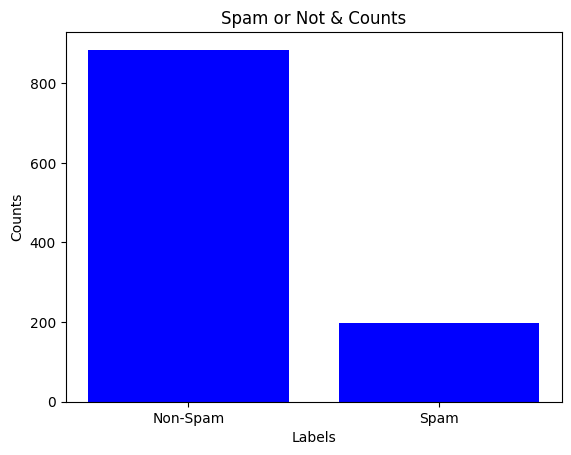

In [55]:
plt.bar(y_values.index,y_values.values,color='b')
plt.xlabel('Labels')
plt.ylabel('Counts')
plt.title('Spam or Not & Counts')

In [56]:
df.drop('S. No.',axis=1,inplace=True)

In [57]:
df['Label'] = df['Label'].map({'Spam': 1, 'Non-Spam': 0})
df

,Message_body,Label
0,Rofl. Its true to its name,0
1,The guy did some bitching but I acted like i'd...,0
2,"Pity, * was in mood for that. So...any other s...",0
3,Will ü b going to esplanade fr home?,0
4,This is the 2nd time we have tried 2 contact u...,1
...,...,...
1077,7 wonders in My WORLD 7th You 6th Ur style 5th...,0
1078,Try to do something dear. You read something f...,0
1079,Sun ah... Thk mayb can if dun have anythin on....,0
1080,"SYMPTOMS when U are in love: ""1.U like listeni...",0


In [58]:
message = df.Message_body
message


,Message_body
0,Rofl. Its true to its name
1,The guy did some bitching but I acted like i'd...
2,"Pity, * was in mood for that. So...any other s..."
3,Will ü b going to esplanade fr home?
4,This is the 2nd time we have tried 2 contact u...
...,...
1077,7 wonders in My WORLD 7th You 6th Ur style 5th...
1078,Try to do something dear. You read something f...
1079,Sun ah... Thk mayb can if dun have anythin on....
1080,"SYMPTOMS when U are in love: ""1.U like listeni..."


In [59]:
#Downloading resources
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [60]:
from nltk.tokenize import TweetTokenizer
tk = TweetTokenizer()
message = message.apply(lambda x:tk.tokenize(x)).apply(lambda x:' '.join(x))
message

,Message_body
0,Rofl . Its true to its name
1,The guy did some bitching but I acted like i'd...
2,"Pity , * was in mood for that . So ... any oth..."
3,Will ü b going to esplanade fr home ?
4,This is the 2nd time we have tried 2 contact u...
...,...
1077,7 wonders in My WORLD 7th You 6th Ur style 5th...
1078,Try to do something dear . You read something ...
1079,Sun ah ... Thk mayb can if dun have anythin on...
1080,"SYMPTOMS when U are in love : "" 1 . U like lis..."


In [61]:
message = message.str.replace('[^a-zA-Z0-9]',' ',regex = True)
message

,Message_body
0,Rofl Its true to its name
1,The guy did some bitching but I acted like i d...
2,Pity was in mood for that So any oth...
3,Will b going to esplanade fr home
4,This is the 2nd time we have tried 2 contact u...
...,...
1077,7 wonders in My WORLD 7th You 6th Ur style 5th...
1078,Try to do something dear You read something ...
1079,Sun ah Thk mayb can if dun have anythin on...
1080,SYMPTOMS when U are in love 1 U like lis...


In [62]:
message = message.apply(lambda x:' '.join([w for w in tk.tokenize(x) if len(w)>=3]))
message

,Message_body
0,Rofl Its true its name
1,The guy did some bitching but acted like inter...
2,Pity was mood for that any other suggestions
3,Will going esplanade home
4,This the 2nd time have tried contact have won ...
...,...
1077,wonders WORLD 7th You 6th style 5th smile 4th ...
1078,Try something dear You read something for exams
1079,Sun Thk mayb can dun have anythin Thk have boo...
1080,SYMPTOMS when are love like listening songs ge...


In [63]:
#stemming
from nltk.stem import SnowballStemmer
st = SnowballStemmer('english')
message = message.apply(lambda x:[st.stem(i.lower()) for i in tk.tokenize(x)]).apply(lambda x:' '.join(x))
message

,Message_body
0,rofl it true it name
1,the guy did some bitch but act like interest b...
2,piti was mood for that ani other suggest
3,will go esplanad home
4,this the 2nd time have tri contact have won th...
...,...
1077,wonder world 7th you 6th style 5th smile 4th p...
1078,tri someth dear you read someth for exam
1079,sun thk mayb can dun have anythin thk have boo...
1080,symptom when are love like listen song get sto...


In [64]:
#removing stopwords
from nltk.corpus import stopwords
sw = stopwords.words('english')
message = message.apply(lambda x:[i for i in tk.tokenize(x) if i not in sw]).apply(lambda x:' '.join(x))
message

,Message_body
0,rofl true name
1,guy bitch act like interest buy someth els nex...
2,piti mood ani suggest
3,go esplanad home
4,2nd time tri contact 750 pound prize claim eas...
...,...
1077,wonder world 7th 6th style 5th smile 4th perso...
1078,tri someth dear read someth exam
1079,sun thk mayb dun anythin thk book lesson pilat...
1080,symptom love like listen song get stop see nam...


In [65]:
#Vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer()
data = vec.fit_transform(message)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 8924 stored elements and shape (1082, 2854)>

In [66]:
y = df['Label'].values
y

array([0, 0, 0, ..., 0, 0, 0], shape=(1082,))

In [67]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(data,y,test_size = 0.3,random_state=42)

In [68]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Initialize the models
model_knn = KNeighborsClassifier()
model_nb = MultinomialNB()
model_dt = DecisionTreeClassifier(random_state=42)
model_rf = RandomForestClassifier(random_state=42)

# Train the models
model_knn.fit(x_train,y_train)
model_nb.fit(x_train, y_train)
model_dt.fit(x_train, y_train)
model_rf.fit(x_train, y_train)

# Predict and calculate accuracies
knn_pred = model_knn.predict(x_test)
nb_pred = model_nb.predict(x_test)
dt_pred = model_dt.predict(x_test)
rf_pred = model_rf.predict(x_test)

print(f"KNN  Accuracy:                    {accuracy_score(y_test, knn_pred):.4f}")
print(f"Multinomial Naive Bayes Accuracy: {accuracy_score(y_test, nb_pred):.4f}")
print(f"Decision Tree Accuracy:           {accuracy_score(y_test, dt_pred):.4f}")
print(f"Random Forest Accuracy:           {accuracy_score(y_test, rf_pred):.4f}")

KNN  Accuracy:                    0.8400
Multinomial Naive Bayes Accuracy: 0.9354
Decision Tree Accuracy:           0.9354
Random Forest Accuracy:           0.9600


In [69]:
import matplotlib.pyplot as plt
s1 = accuracy_score(y_test, knn_pred)
s2 = accuracy_score(y_test, nb_pred)
s3 = accuracy_score(y_test, dt_pred)
s4 = accuracy_score(y_test, rf_pred)

In [70]:
acc_df = pd.DataFrame({'models':['KNN','Naive_Bays','Decision Tree','Random Forest'],'values':[s1,s2,s3,s4]})

Text(0.5, 1.0, 'Accuracy & Score')

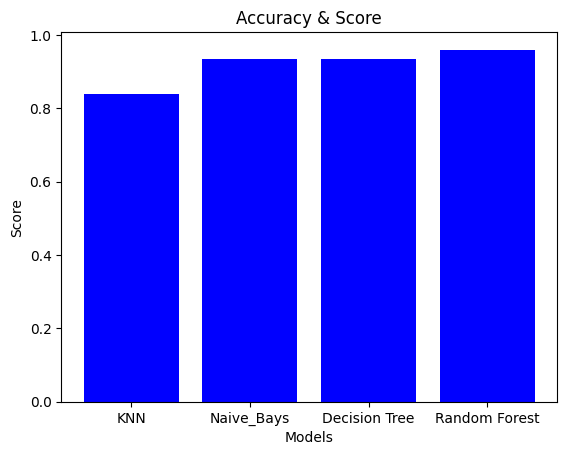

In [71]:
plt.bar(acc_df['models'],acc_df['values'],color='b')
plt.xlabel('Models')
plt.ylabel('Score')
plt.title('Accuracy & Score')

In [75]:
message = ['WINNER! You have won a 1000 GBP prize! Claim your free gift card now by calling 09061701461. Easy cash award!']
v_message = vec.transform(message)
predy = model_nb.predict(v_message)
if predy == 1:
  print('Spam')
else:
  print('Not Spam')

Spam
